# 05 - Gradient Boosting
**Owner:** Sriniket Deeduvanu

Gradient boosting builds an ensemble of small decision trees one after another. Each new tree is fitted to the errors of the current ensemble (the gradient of the loss) and its predictions are added with a shrinkage factor, the learning rate. Unlike a random forest, which averages independent deep trees, boosting combines many shallow trees that each correct their predecessors, which often gives higher accuracy on tabular data.

This notebook uses scikit-learn's `HistGradientBoostingClassifier`. It is a histogram-based implementation: each feature is binned into at most 255 buckets, which makes training fast on 200,000+ rows. It follows the same idea as LightGBM and needs no extra installation.

**Design decisions**
- Inputs come from `build_tree_preprocessor` (ordinal-encoded categoricals, raw `age`, geo IDs as numbers). No scaling is needed.
- The selection metric is validation micro-F1, the project metric.
- Nine configurations are compared, varying the learning rate (`learning_rate`), the maximum number of boosting iterations (`max_iter`) and the maximum number of leaves per tree (`max_leaf_nodes`). L2 regularisation is fixed at 1.0. The first six form the initial search. The last three extend it towards more capacity, because the best of the first six used all 250 iterations without early stopping and every lower-capacity variant scored lower.
- Early stopping is enabled: 10% of the training split is held out internally and training stops when its loss has not improved for 10 iterations. The validation split is therefore not used to decide when to stop.
- Training and validation micro-F1 are reported for every configuration to show how much each one overfits.
- Permutation importance (5 repeats on 5,000 validation buildings) is computed for the selected model and saved to `results/metrics/` for the comparison notebook.

In [1]:
import os, sys
from pathlib import Path

# --- Colab only: clone the repo and move into it ---
REPO = "ML-Project-Earthquake-Damage"
GITHUB_URL = "https://github.com/ayaanGH06/ML-Project-Earthquake-Damage.git"  # private repo: use a token URL in Colab, never commit it

if "google.colab" in sys.modules and not os.path.exists("src"):
    if not os.path.exists(REPO):
        !git clone {GITHUB_URL}
    %cd {REPO}
    !pip install -q -r requirements.txt

# --- Local Jupyter: notebooks run from notebooks/, so go up to the repo root ---
if Path.cwd().name == "notebooks":
    os.chdir("..")

# --- Data: the 3 CSVs must be in data/raw/ (see README for the download link) ---
DATA_DIR = Path("data/raw")
needed = ["train_values.csv", "train_labels.csv", "test_values.csv"]
missing = [f for f in needed if not (DATA_DIR / f).exists()]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} in {DATA_DIR.resolve()}. "
        "Download them from the Google Drive link in the README and place them in data/raw/."
    )

from src.data import load_raw, train_val_split, build_scaled_preprocessor, build_tree_preprocessor
from src.evaluate import evaluate_model, micro_f1

X, y, X_test = load_raw(DATA_DIR)
X_train, X_val, y_train, y_val = train_val_split(X, y)
print(X_train.shape, X_val.shape)

(208480, 38) (52121, 38)


## 1. Hyperparameter search

In [2]:
import json
import time
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score
from sklearn.pipeline import Pipeline
from src.evaluate import save_permutation_importance

METRIC_DIR = Path("results/metrics")
METRIC_DIR.mkdir(parents=True, exist_ok=True)

configs = [
    {"name": "Baseline", "learning_rate": 0.1, "max_iter": 150, "max_leaf_nodes": 31},
    {"name": "Lower learning rate", "learning_rate": 0.05, "max_iter": 150, "max_leaf_nodes": 31},
    {"name": "More iterations", "learning_rate": 0.1, "max_iter": 250, "max_leaf_nodes": 31},
    {"name": "Fewer leaves", "learning_rate": 0.1, "max_iter": 150, "max_leaf_nodes": 15},
    {"name": "Higher learning rate", "learning_rate": 0.15, "max_iter": 150, "max_leaf_nodes": 31},
    {"name": "Combined tuning", "learning_rate": 0.05, "max_iter": 250, "max_leaf_nodes": 15},
    {"name": "400 iterations", "learning_rate": 0.1, "max_iter": 400, "max_leaf_nodes": 31},
    {"name": "More leaves", "learning_rate": 0.1, "max_iter": 250, "max_leaf_nodes": 63},
    {"name": "500 iterations, more leaves", "learning_rate": 0.1, "max_iter": 500, "max_leaf_nodes": 63},
]

results = []
best_model, best_config, best_f1 = None, None, -1

for config in configs:
    t0 = time.time()
    model = Pipeline([
        ("preprocessor", build_tree_preprocessor(X_train)),
        ("classifier", HistGradientBoostingClassifier(
            learning_rate=config["learning_rate"],
            max_iter=config["max_iter"],
            max_leaf_nodes=config["max_leaf_nodes"],
            l2_regularization=1.0,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=10,
            random_state=42,
        )),
    ])
    model.fit(X_train, y_train)
    train_f1 = f1_score(y_train, model.predict(X_train), average="micro")
    val_pred = model.predict(X_val)
    val_f1 = f1_score(y_val, val_pred, average="micro")
    results.append({
        "configuration": config["name"],
        "learning_rate": config["learning_rate"],
        "max_iter": config["max_iter"],
        "max_leaf_nodes": config["max_leaf_nodes"],
        "actual_iterations": model.named_steps["classifier"].n_iter_,
        "train_micro_f1": train_f1,
        "val_micro_f1": val_f1,
        "val_macro_f1": f1_score(y_val, val_pred, average="macro"),
        "seconds": round(time.time() - t0),
    })
    print(f"{config['name']:>28}: train {train_f1:.4f} | val {val_f1:.4f} | "
          f"{results[-1]['actual_iterations']} iterations | {results[-1]['seconds']} s")
    if val_f1 > best_f1:
        best_model, best_config, best_f1 = model, config, val_f1

results_df = pd.DataFrame(results).sort_values("val_micro_f1", ascending=False).reset_index(drop=True)
print()
display(results_df.round(4))
print("Selected configuration:", best_config)

                    Baseline: train 0.7376 | val 0.7277 | 150 iterations | 12 s
         Lower learning rate: train 0.7198 | val 0.7161 | 150 iterations | 13 s
             More iterations: train 0.7523 | val 0.7343 | 250 iterations | 21 s
                Fewer leaves: train 0.7194 | val 0.7160 | 150 iterations | 10 s
        Higher learning rate: train 0.7489 | val 0.7309 | 150 iterations | 12 s
             Combined tuning: train 0.7122 | val 0.7097 | 250 iterations | 16 s
              400 iterations: train 0.7675 | val 0.7396 | 400 iterations | 28 s
                 More leaves: train 0.7774 | val 0.7413 | 250 iterations | 26 s
 500 iterations, more leaves: train 0.7913 | val 0.7459 | 350 iterations | 34 s



,configuration,learning_rate,max_iter,max_leaf_nodes,actual_iterations,train_micro_f1,val_micro_f1,val_macro_f1,seconds
0,"500 iterations, more leaves",0.10,500,63,350,0.7913,0.7459,0.6929,34
1,More leaves,0.10,250,63,250,0.7774,0.7413,0.6858,26
2,400 iterations,0.10,400,31,400,0.7675,0.7396,0.6838,28
3,More iterations,0.10,250,31,250,0.7523,0.7343,0.6764,21
4,Higher learning rate,0.15,150,31,150,0.7489,0.7309,0.6717,12
5,Baseline,0.10,150,31,150,0.7376,0.7277,0.6666,12
6,Lower learning rate,0.05,150,31,150,0.7198,0.7161,0.6483,13
7,Fewer leaves,0.10,150,15,150,0.7194,0.7160,0.6491,10
8,Combined tuning,0.05,250,15,250,0.7122,0.7097,0.6413,16


Selected configuration: {'name': '500 iterations, more leaves', 'learning_rate': 0.1, 'max_iter': 500, 'max_leaf_nodes': 63}


Model capacity is what matters most. Every configuration that reduces capacity scores below the baseline (0.7277): a lower learning rate gives 0.7161, fewer leaves 0.7160 and the two combined 0.7097. Every configuration that adds capacity improves on it: a higher learning rate gives 0.7309, 250 iterations 0.7343, 400 iterations 0.7396, 63 leaves 0.7413, and 500 iterations with 63 leaves 0.7459. More leaves helps more than more iterations (0.7413 against 0.7343 for the same 250 iterations with 31 leaves).

The selected configuration stopped at 350 of a maximum of 500 iterations, so early stopping rather than the iteration cap ended training. The 400-iteration run with 31 leaves, in contrast, used all 400 iterations and had not converged. Because the selected setting also uses the largest number of leaves tested (63), even larger trees might improve the score further; this was not explored.

## 2. Selected model: evaluation and feature importance
The selected configuration is evaluated on the validation split with the shared `evaluate_model`, which saves the confusion matrix and the metrics used by the comparison notebook.

gradient_boosting: micro-F1 = 0.7459
              precision    recall  f1-score   support

           1       0.69      0.52      0.59      5025
           2       0.74      0.85      0.79     29652
           3       0.77      0.63      0.69     17444

    accuracy                           0.75     52121
   macro avg       0.73      0.67      0.69     52121
weighted avg       0.75      0.75      0.74     52121



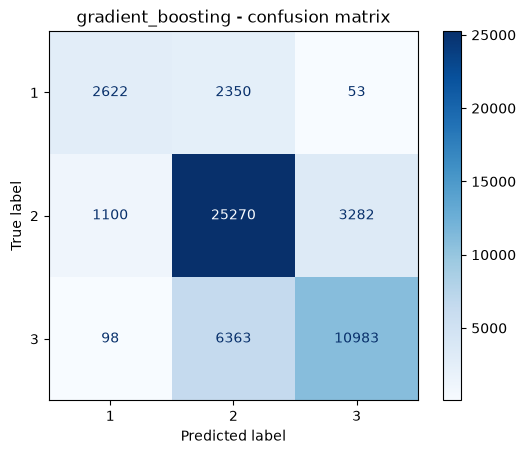

Training micro-F1:   0.7913
Validation micro-F1: 0.7459
Train - validation gap: 0.0455
Iterations used: 350 of a maximum of 500

Top 10 features by permutation importance (5,000 validation rows, 5 repeats):
geo_level_1_id                         0.1752
geo_level_2_id                         0.0714
geo_level_3_id                         0.0336
has_superstructure_mud_mortar_stone    0.0170
age                                    0.0142
area_percentage                        0.0102
height_percentage                      0.0077
has_superstructure_timber              0.0074
ground_floor_type                      0.0072
roof_type                              0.0071


In [3]:
y_val_pred_gb = best_model.predict(X_val)
gb_f1 = evaluate_model("gradient_boosting", y_val, y_val_pred_gb)

best_row = results_df.iloc[0]
print(f"Training micro-F1:   {best_row['train_micro_f1']:.4f}")
print(f"Validation micro-F1: {best_row['val_micro_f1']:.4f}")
print(f"Train - validation gap: {best_row['train_micro_f1'] - best_row['val_micro_f1']:.4f}")
print(f"Iterations used: {int(best_row['actual_iterations'])} of a maximum of {int(best_row['max_iter'])}")

with open(METRIC_DIR / "gradient_boosting_params.json", "w") as f:
    json.dump({"configuration": best_config,
               "iterations_used": int(best_row["actual_iterations"]),
               "train_micro_f1": float(best_row["train_micro_f1"]),
               "val_micro_f1": float(best_row["val_micro_f1"])}, f, indent=2)
results_df.to_json(METRIC_DIR / "gradient_boosting_tuning.json", orient="records", indent=2)

fi = save_permutation_importance("gradient_boosting", best_model, X_val, y_val)
top = pd.Series(fi["importance_mean"]).nlargest(10)
print(f"\nTop 10 features by permutation importance ({fi['n_rows']:,} validation rows, {fi['n_repeats']} repeats):")
print(top.round(4).to_string())

The selected model reaches a validation micro-F1 of 0.7459 and a macro-F1 of 0.6929, the best of the four models on both. Its training-validation gap is 0.046 (0.7913 against 0.7459), far smaller than the random forest's 0.137, so it generalises better. Per grade, recall is 0.52, 0.85 and 0.63 and precision is 0.69, 0.74 and 0.77. Compared with the random forest, the gain comes mainly from the minority classes: recall rises from 0.45 to 0.52 for grade 1 and from 0.59 to 0.63 for grade 3, while grade 2 recall is almost unchanged (0.85 against 0.86).

By permutation importance, `geo_level_1_id` (a drop in micro-F1 of about 0.18 when shuffled), `geo_level_2_id` (0.071) and `geo_level_3_id` (0.034) occupy the top three positions, followed by `has_superstructure_mud_mortar_stone` (0.017) and `age` (0.014). Boosting relies on the finer location columns more than the random forest does (geo level 2: 0.071 against 0.038), and `age` ranks fifth here against tenth for the forest.